Depth 1   : train 0.81 val 0.81
Depth 3   : train 0.82 val 0.79
Depth 5   : train 0.83 val 0.78
Depth 10  : train 0.92 val 0.73
Depth None: train 1.00 val 0.65


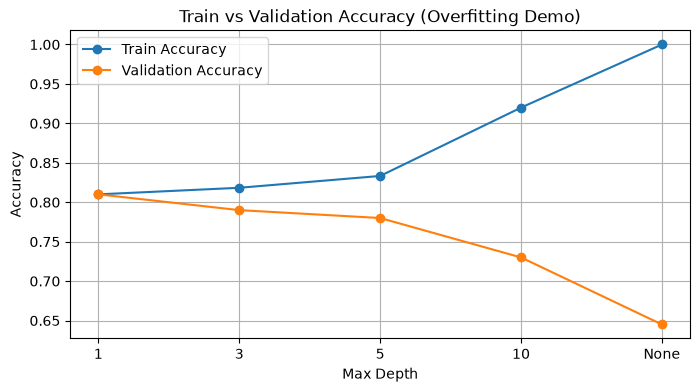


CV: 0.81 +/- 0.00


In [1]:
#1st task
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 1. Dataset Generation
np.random.seed(42)
n_samples = 1000

df = pd.DataFrame({
    'income': np.random.exponential(50000, n_samples) + 20000,
    'loan_amount': np.random.exponential(15000, n_samples) + 5000,
    'credit_score': np.random.randint(550, 850, n_samples),
    'default': np.random.choice([0, 1], n_samples, p=[0.8, 0.2])
})

X = df.drop(columns=['default'])
y = df['default']

# 2. Train / Validation / Test Split (60 / 20 / 20 Stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full)

# Impute missing values for numeric demonstration
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)

# 3. Overfitting: DecisionTreeClassifier (depth 1, 3, 5, 10, None)
depths = [1, 3, 5, 10, None]
train_accs, val_accs = [], []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train_imp, y_train)
    t_acc = dt.score(X_train_imp, y_train)
    v_acc = dt.score(X_val_imp, y_val)
    train_accs.append(t_acc)
    val_accs.append(v_acc)
    print(f"Depth {str(d):4s}: train {t_acc:.2f} val {v_acc:.2f}")

# Plotting Overfitting Curve
plt.figure(figsize=(8, 4))
plt.plot([str(d) for d in depths], train_accs, label='Train Accuracy', marker='o')
plt.plot([str(d) for d in depths], val_accs, label='Validation Accuracy', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Train vs Validation Accuracy (Overfitting Demo)')
plt.legend()
plt.grid(True)
plt.show()

# 4. 5-Fold Cross Validation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
lr = LogisticRegression(max_iter=1000)
cv_scores = cross_val_score(lr, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"\nCV: {cv_scores.mean():.2f} +/- {cv_scores.std():.2f}")

In [3]:
#2nd task
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FunctionTransformer
from sklearn.linear_model import LogisticRegression
import joblib

# 1. Generate Dataset
np.random.seed(42)
n_samples = 1000

df = pd.DataFrame({
    'income': np.random.exponential(50000, n_samples) + 20000,
    'loan_amount': np.random.exponential(15000, n_samples) + 5000,
    'credit_score': np.random.randint(550, 850, n_samples),
    'employment_type': np.random.choice(['Salaried', 'Self-Employed', 'Business', 'Unemployed'], n_samples, p=[0.5, 0.3, 0.15, 0.05]),
    'education': np.random.choice(['High School', 'Graduate', 'Post-Graduate'], n_samples, p=[0.3, 0.5, 0.2]),
    'application_date': pd.date_range(start='2023-01-01', periods=n_samples, freq='h'),
    'default': np.random.choice([0, 1], n_samples, p=[0.8, 0.2])
})

# Introduce missing values to test Imputers
df.loc[df.sample(50, random_state=42).index, 'income'] = np.nan
df.loc[df.sample(30, random_state=42).index, 'employment_type'] = np.nan

X = df.drop(columns=['default'])
y = df['default']

# Split data
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full)

# 2. Feature Engineering Function
def engineer_features(data):
    df_f = data.copy()
    df_f['application_date'] = pd.to_datetime(df_f['application_date'])
    df_f['app_month'] = df_f['application_date'].dt.month
    df_f['app_dayofweek'] = df_f['application_date'].dt.day_of_week
    df_f['income_loan_ratio'] = df_f['income'] / (df_f['loan_amount'] + 1)
    df_f['log_income'] = np.log1p(df_f['income'].fillna(df_f['income'].median()))
    df_f = df_f.drop(columns=['application_date'])
    return df_f

# 3. Define Feature Groups
numeric_features = ['income', 'loan_amount', 'credit_score', 'app_month', 'app_dayofweek', 'income_loan_ratio', 'log_income']
categorical_features = ['employment_type']
ordinal_features = ['education']
education_categories = [['High School', 'Graduate', 'Post-Graduate']]

# 4. ColumnTransformer & Pipeline Setup
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
        ('ord', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=education_categories))]), ordinal_features)
    ]
)

pipeline = Pipeline(steps=[
    ('fe', FunctionTransformer(engineer_features)),
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# 5. Fit Pipeline and Check Accuracy
pipeline.fit(X_train, y_train)
val_acc = pipeline.score(X_val, y_val)
print(f"Pipeline CV accuracy: {val_acc:.2f}")

# 6. Save with Joblib and Predict on 3 New Raw Rows
joblib.dump(pipeline, 'loan_pipeline.pkl')
loaded_pipeline = joblib.load('loan_pipeline.pkl')

new_rows = X_val.iloc[:3]
preds = loaded_pipeline.predict(new_rows)
print(f"Predictions for 3 new rows: {list(preds)}")

Pipeline CV accuracy: 0.81
Predictions for 3 new rows: [np.int64(0), np.int64(0), np.int64(0)]
